# 02 · Histograms and empirical probability

A histogram groups nearby numerical observations into intervals so that we can see the shape of a distribution. It can reveal concentration, skewness, multiple groups, and unusual values that a mean alone would miss. Its vertical scale determines how to read probabilities.

```mermaid
flowchart LR
    A[Individual values] --> B[Choose bin edges]
    B --> C[Count observations]
    C --> D[Relative frequency]
    D --> E[Density and area]
    E --> F[Estimate probabilities with uncertainty]
```

**Learning route:** bins → counts → proportions → density → limitations. Prerequisites: [Chapter 1](../01_Fundamental_Concepts_in_Statistics/01_Fundamental_Concepts_in_Statistics.md).

## 1. Build a histogram by hand

Imagine measuring how many minutes twenty independent printing jobs spend in a workshop queue:

$$2,3,4,4,5,6,6,7,8,8,9,10,11,12,12,13,14,16,18,22.$$

These are invented teaching data. Use edges $0,5,10,15,20,25$. Our convention is **left inclusive, right exclusive**: $[5,10)$ includes 5 but not 10. The last bin also includes its rightmost edge, matching NumPy's convention.

| Interval, minutes | Count $c_j$ | Relative frequency $c_j/n$ |
|---|---:|---:|
| $[0,5)$ | 4 | 0.20 |
| $[5,10)$ | 7 | 0.35 |
| $[10,15)$ | 6 | 0.30 |
| $[15,20)$ | 2 | 0.10 |
| $[20,25]$ | 1 | 0.05 |
| **Total** | **20** | **1.00** |

The interval from 5 through just below 15 minutes contains $7+6=13$ jobs, so its empirical probability is $13/20=0.65$. That calculation is a statement about this sample. Using it to predict future jobs assumes the sample represents a sufficiently stable future process.

![Count, relative-frequency, and density histograms](figure/three_scales.png)

**Notebook setup.** Run all cells from top to bottom. Figures are saved in this chapter's `figure/` folder. Restart the kernel and run all after changing a simulation. See the repository README for installation.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

# Works when Jupyter starts in either this chapter or the repository root.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "scripts" / "build_notebooks.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook inside the cloned course repository.")
FIGURE_DIR = ROOT / '02_Histogram' / "figure"
FIGURE_DIR.mkdir(exist_ok=True)
plt.rcParams.update({
    "figure.figsize": (9, 4.8), "figure.dpi": 110,
    "font.size": 11, "axes.titlesize": 14, "axes.labelsize": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.prop_cycle": plt.cycler(color=["#087E8B", "#D55E00", "#7251A2", "#4477AA"]),
    "savefig.facecolor": "white", "axes.facecolor": "#FAFBFC",
})
TEAL, ORANGE, PURPLE = "#087E8B", "#D55E00", "#7251A2"

def save_figure(fig, name):
    """Save the exact figure used by Markdown and display it in the notebook."""
    fig.savefig(FIGURE_DIR / f"{name}.png", dpi=180, bbox_inches="tight")
    fig.savefig(FIGURE_DIR / f"{name}.svg", bbox_inches="tight")
    display(fig)
    plt.close(fig)

print("All datasets in this notebook are synthetic teaching examples.")


All datasets in this notebook are synthetic teaching examples.


,left_edge,right_edge,count,proportion,density
0,0,5,4,0.20,0.04
1,5,10,7,0.35,0.07
2,10,15,6,0.30,0.06
3,15,20,2,0.10,0.02
4,20,25,1,0.05,0.01


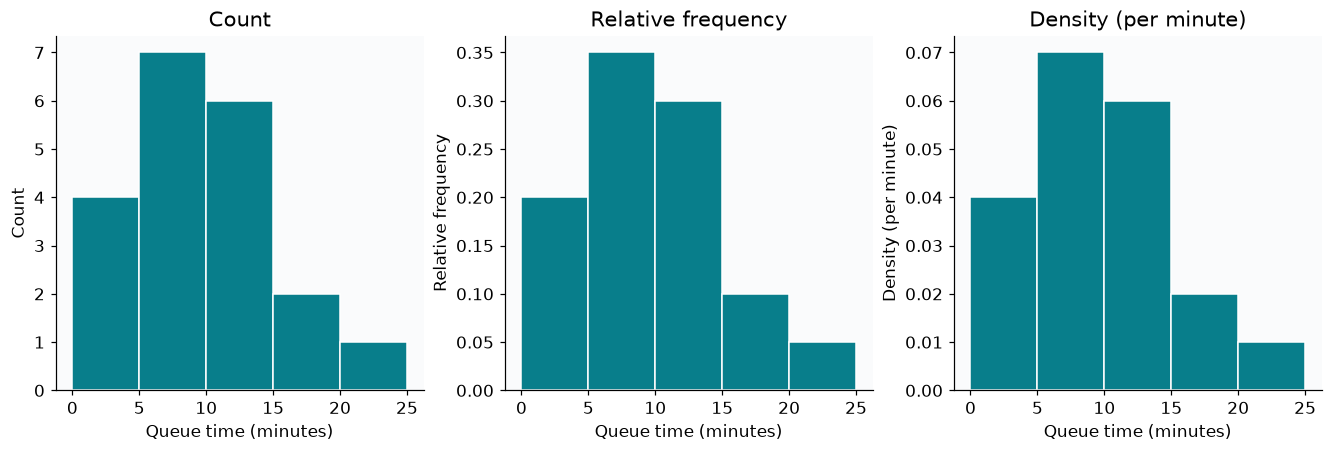

In [2]:
waits = np.array([2,3,4,4,5,6,6,7,8,8,9,10,11,12,12,13,14,16,18,22])
edges = np.arange(0, 26, 5)
counts, _ = np.histogram(waits, bins=edges)
assert np.array_equal(counts, [4,7,6,2,1])
display(pd.DataFrame({"left_edge": edges[:-1], "right_edge": edges[1:],
                      "count": counts, "proportion": counts/len(waits),
                      "density": counts/(len(waits)*np.diff(edges))}))
fig, axes = plt.subplots(1, 3, figsize=(12, 4), layout="constrained")
for ax, heights, label in zip(axes, [counts, counts/20, counts/100],
                            ["Count", "Relative frequency", "Density (per minute)"]):
    ax.bar(edges[:-1], heights, width=5, align="edge", color=TEAL, edgecolor="white")
    ax.set(xlabel="Queue time (minutes)", ylabel=label, title=label, xticks=edges)
save_figure(fig, "three_scales")

## 2. Three vertical scales, three interpretations

A **count histogram** has height $c_j$. Counts sum to $n$. A **relative-frequency histogram** has height $c_j/n$. Heights sum to one, but its area need not be one.

A **density histogram** has height

$$h_j=\frac{c_j}{n\,w_j},$$

where $w_j$ is the width of bin $j$. Its rectangle area is $h_jw_j=c_j/n$, so the total area is one. Density has units reciprocal to the horizontal variable. For time in minutes, density is “per minute.” In the bin $[5,10)$, height is $7/(20\times5)=0.07$ per minute and area is $0.07\times5=0.35$.

This distinction becomes essential with unequal bin widths. Suppose one bin spans 0–5 minutes and another spans 5–15. The second is twice as wide and has twice as much opportunity to collect observations even if the underlying density is constant. Plotting raw counts as if height represented concentration would be misleading. Divide by width and compare areas.

![Unequal-width bins with correct density scaling](figure/unequal_bins.png)

**Read the plot:** the wide rectangle can contain more probability without being proportionally taller. The labels report its area, which is the observed fraction of jobs in that interval. Integrating the density histogram means adding height times width, not adding heights.

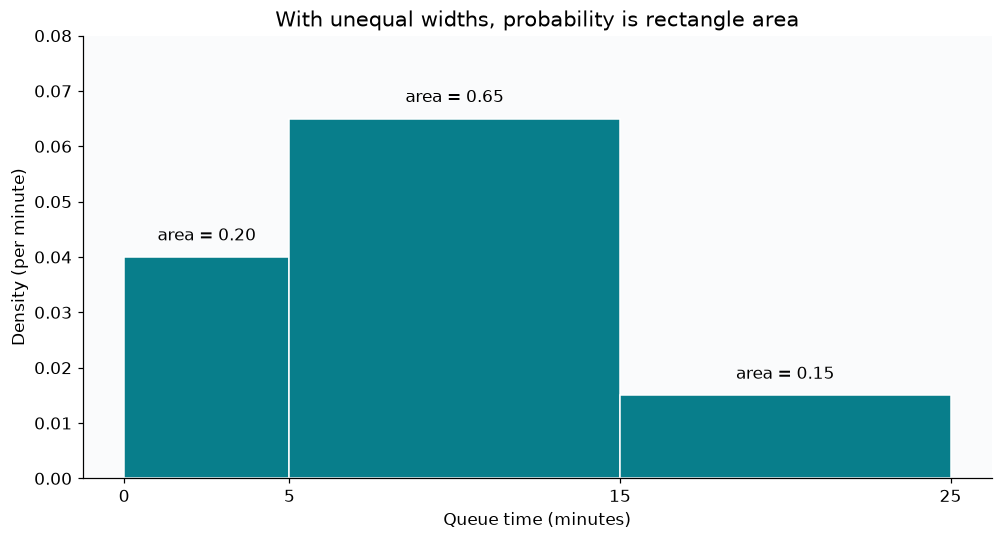

In [3]:
unequal = np.array([0,5,15,25])
c, _ = np.histogram(waits, bins=unequal)
widths = np.diff(unequal)
density = c / (len(waits) * widths)
assert np.isclose(np.sum(density * widths), 1)
fig, ax = plt.subplots(layout="constrained")
ax.bar(unequal[:-1], density, width=widths, align="edge", edgecolor="white", color=TEAL)
for left, width, height, count in zip(unequal[:-1], widths, density, c):
    ax.text(left+width/2, height+.003, f"area = {count/20:.2f}", ha="center")
ax.set(xlabel="Queue time (minutes)", ylabel="Density (per minute)", ylim=(0,.08),
       xticks=unequal, title="With unequal widths, probability is rectangle area")
save_figure(fig, "unequal_bins")

## 3. Bins are choices, not discoveries

Very wide bins can hide a second cluster. Very narrow bins can turn ordinary sampling noise into apparent peaks. Shifting the bin origin can change the visible shape even when the width stays fixed. A pattern that survives several reasonable choices is more convincing than one that appears under only a carefully selected choice.

Common starting rules include Sturges' rule, approximately $1+\log_2n$ bins, and the Freedman–Diaconis width,

$$w=2\,IQR\,n^{-1/3}.$$

The latter uses a spread measure less sensitive to extremes than SD. It is still a starting point, and it can be unhelpful when the IQR is zero or the sample is tiny. Choose bins in meaningful units, inspect alternatives, and use the same edges when directly comparing groups. `np.histogram_bin_edges(x, bins="fd")` supplies a reproducible starting choice.

![The same simulated observations shown with different bins](figure/bin_choices.png)

**Notebook experiment:** the three panels use exactly the same observations from a mixture of two normal populations. Change the number of bins or their starting edge, without regenerating the observations. Which visible features remain? Do not claim that every bump represents a real subpopulation.

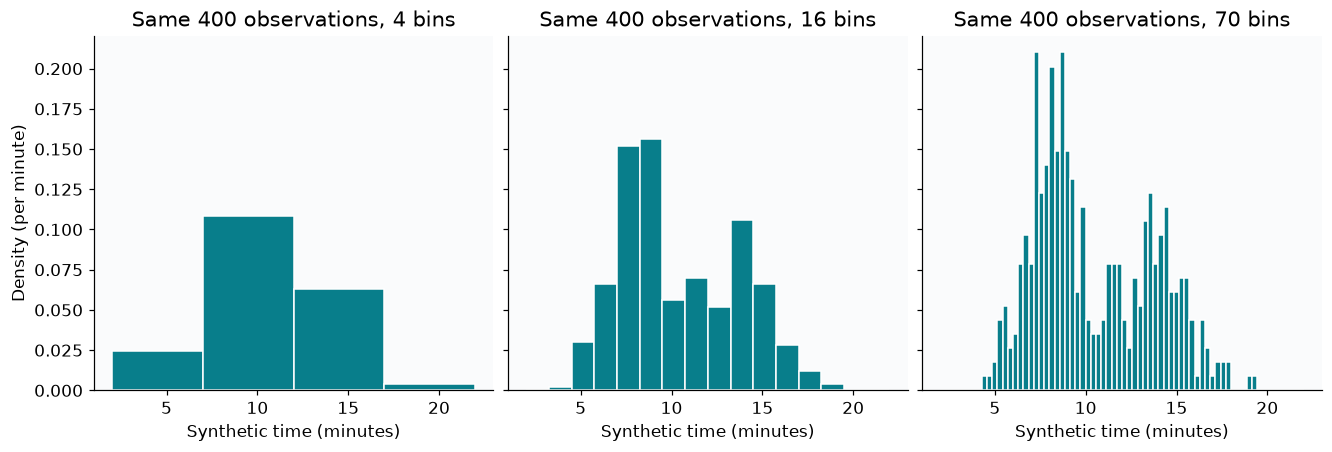

Freedman-Diaconis suggested number of bins: 10


In [4]:
rng = np.random.default_rng(202)
mixture = np.r_[rng.normal(8, 1.3, 230), rng.normal(14, 1.8, 170)]
fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True, layout="constrained")
for ax, bins in zip(axes, [4, 16, 70]):
    ax.hist(mixture, bins=np.linspace(2,22,bins+1), density=True, color=TEAL, edgecolor="white")
    ax.set(xlabel="Synthetic time (minutes)", title=f"Same 400 observations, {bins} bins")
axes[0].set_ylabel("Density (per minute)")
save_figure(fig, "bin_choices")
print("Freedman-Diaconis suggested number of bins:", len(np.histogram_bin_edges(mixture, bins="fd"))-1)

## 4. Probabilities do not require bins

For an event $A$, the empirical probability is

$$\widehat P(A)=\frac1n\sum_{i=1}^n\mathbf 1\{x_i\in A\}.$$

The indicator $\mathbf1$ is one when the condition holds and zero otherwise. This formula avoids bin-boundary ambiguity. For example, to estimate $P(X>12)$ in the queue data, count 13, 14, 16, 18, and 22: $5/20=0.25$.

If a requested interval cuts through a bin, the histogram alone cannot reveal exactly how many observations lie inside the partial bin. Assuming constant density within that bin gives an approximation. The original observations give the exact empirical fraction.

The **empirical cumulative distribution function**, or ECDF, is

$$\widehat F(t)=\frac{\#\{i:x_i\le t\}}n.$$

It increases by $1/n$ at each observation, or by a larger jump at ties. It needs no bin choices and makes threshold probabilities easy to read. Here $\widehat F(12)=15/20=0.75$, so $\widehat P(X>12)=1-0.75=0.25$.

![Empirical cumulative probabilities for queue time](figure/ecdf.png)

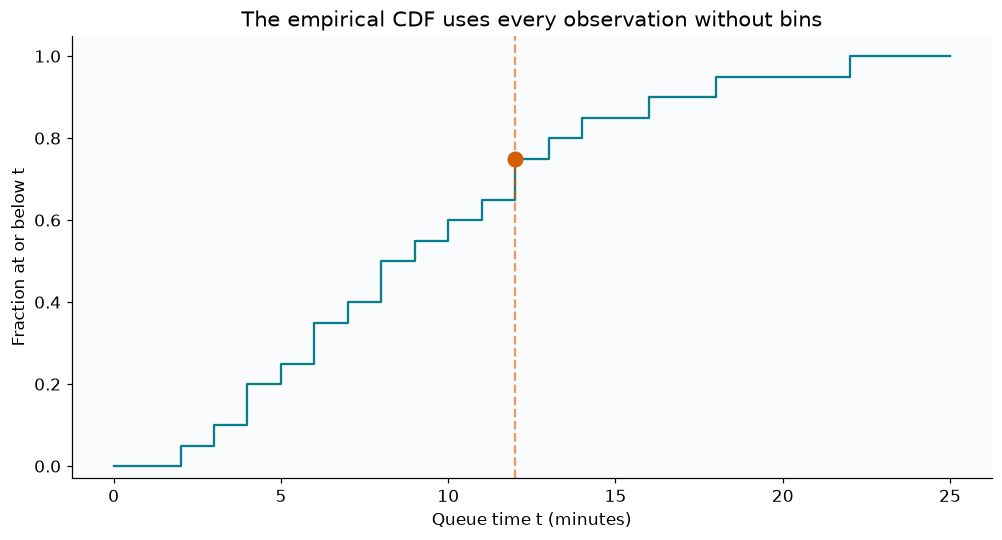

P-hat(X > 12) = 0.25
95% upper bound after zero events in 20 trials: 0.13910834066826516


In [5]:
sorted_waits = np.sort(waits)
fig, ax = plt.subplots(layout="constrained")
ax.step(np.r_[0, sorted_waits, 25], np.r_[0, np.arange(1,21)/20, 1], where="post", color=TEAL)
ax.scatter([12], [(waits<=12).mean()], color=ORANGE, s=90, zorder=3)
ax.axvline(12, color=ORANGE, ls="--", alpha=.6)
ax.set(xlabel="Queue time t (minutes)", ylabel="Fraction at or below t", ylim=(-.03,1.05),
       title="The empirical CDF uses every observation without bins")
save_figure(fig, "ecdf")
print("P-hat(X > 12) =", (waits>12).mean())
print("95% upper bound after zero events in 20 trials:", 1-.05**(1/20))

## 5. Empty bins are not proof of impossibility

No observed queue time exceeded 25 minutes. Its empirical frequency is zero, but a rare future delay could still exceed 25. In $n$ independent Bernoulli trials with the same event probability $p$ on each trial, the probability of seeing zero occurrences is $(1-p)^n$.

### Deriving the probability of zero occurrences

A **Bernoulli trial** records one of two outcomes: the event occurs or it does not. Here, one trial is one observed queue time, and the event is “the queue time exceeds 25 minutes.” Let $B_i=1$ if that event occurs on trial $i$, and $B_i=0$ otherwise. The probability $p$ refers to the event occurring on **one trial**.

1. **For one trial, the probability of no event is $1-p$.** The two possible outcomes exhaust all possibilities, so their probabilities sum to one:

   $$P(B_i=0)=1-P(B_i=1)=1-p.$$

2. **For two independent trials, multiply the probabilities.** Seeing zero occurrences means that the event does not occur on the first trial **and** does not occur on the second. Independence lets us multiply their individual probabilities:

   $$P(B_1=0,B_2=0)=P(B_1=0)P(B_2=0)=(1-p)(1-p)=(1-p)^2.$$

3. **For $n$ independent trials, repeat the multiplication $n$ times.** Let $S=\sum_{i=1}^{n}B_i$ count the total number of occurrences. The condition $S=0$ means every trial has outcome zero:

   $$\begin{aligned}
   P(S=0)
   &=P(B_1=0,\ldots,B_n=0)\\
   &=\prod_{i=1}^{n}P(B_i=0)\\
   &=\underbrace{(1-p)(1-p)\cdots(1-p)}_{n\text{ factors}}\\
   &=(1-p)^n.
   \end{aligned}$$

   The superscript $n$ is an **exponent**: multiply $1-p$ by itself $n$ times. It does not mean multiplying $1-p$ by the number $n$.

**Numerical example.** Suppose the true probability of a queue time exceeding 25 minutes is $p=0.05$, and we observe $n=20$ independent queue times. Then

$$P(S=0)=(1-0.05)^{20}=0.95^{20}\approx0.3585.$$

There is about a **35.85% chance of seeing no such delays**, even though each trial has a 5% chance of one. An empty bin can therefore occur when the event's true probability is positive. The complementary probability of seeing **at least one** such delay is $P(S\ge1)=1-(1-p)^n\approx0.6415$, or 64.15%. The value $p=0.05$ is an assumption for this illustration, not a value inferred from the zero observed events.

**Why the assumptions matter.** Multiplying the individual probabilities requires independence across the trials. For example, queue times influenced by the same temporary service outage may be dependent. If trials are independent but have different event probabilities $p_i$, the probability of zero occurrences is $\prod_{i=1}^{n}(1-p_i)$; it reduces to $(1-p)^n$ when all those probabilities equal $p$.

### Connecting zero occurrences to an upper bound

One useful benchmark solves $(1-p)^n=0.05$, giving a one-sided 95% upper bound after zero events:

$$p_U=1-0.05^{1/n}.$$

With only twenty trials, $p_U\approx0.139$. Zero observed events leaves substantial uncertainty. For larger $n$, the approximation $p_U\approx3/n$ is the “rule of three.” This requires independent representative trials and a defined event; choosing an event after inspecting many gaps changes the inferential problem.

More generally, a histogram describes observed data. It cannot fix a biased sample, identify a causal effect, or show time dependence after the time order has been discarded. A run chart may reveal a machine slowing over the day even when its histogram looks ordinary.

## 6. Practical reading checklist

Identify the measured variable and units, then read the vertical-axis label. Check that bin boundaries cover all observations and ask whether groups use compatible scales. Look for overall shape before interpreting individual bumps. Report sample size. For small samples, show a dot plot alongside the histogram so no observations disappear into a bar.

Do not confuse a histogram with a categorical bar chart. Numerical intervals have an order, a width, and meaningful distances. Categories such as printer brands do not have those properties; their bar widths do not encode a continuous measurement scale.

## 7. Practice

1. Eight synthetic travel distances are 1, 2, 2, 3, 5, 6, 7, 9 km. Using bins $[0,3),[3,6),[6,10]$, find counts, probabilities, and density heights.
2. What is the empirical probability of a distance at least 6 km? What is $\widehat F(6)$?
3. A density histogram has height 0.2 per second over an interval of width 3 seconds. What probability does its area represent?
4. Why can a valid density exceed one?
5. After zero failures in 100 independent tests, calculate the one-sided 95% upper bound on the failure probability.

## 8. Worked answers

1. Counts are 3, 2, 3; proportions are $3/8,2/8,3/8$. Widths are 3, 3, 4, so heights are $1/8\approx0.125$, $1/12\approx0.0833$, and $3/32\approx0.09375$ per km. The areas sum to one.

   **Assign each observation to its bin first.** The interval $[0,3)$ includes 0 but excludes 3, so the observed value 3 belongs to $[3,6)$. Similarly, 6 belongs to $[6,10]$. The final bin includes its right endpoint, 10, although there is no 10 in this sample. Both observations equal to 2 are counted separately.

   **Use the formulas.** For bin $B_j$ with lower boundary $a_j$ and upper boundary $b_j$, and $n=8$ observations,

   $$c_j=\sum_{i=1}^{n}\mathbf 1\{x_i\in B_j\},\qquad
   w_j=b_j-a_j,\qquad
   \hat p_j=\frac{c_j}{n},\qquad
   h_j=\frac{\hat p_j}{w_j}=\frac{c_j}{n w_j}.$$

   The indicator contributes 1 for each observation inside the bin and 0 otherwise, so $c_j$ is its count. The width $w_j$ is measured in km, the empirical probability $\hat p_j$ is unitless, and the density height $h_j$ has units of $\mathrm{km}^{-1}$. The widths are $3-0=3$, $6-3=3$, and $10-6=4$ km. Substituting the counts and widths gives:

   | Bin (km) | Observed distances (km) | Count $c_j$ | Width $w_j$ (km) | Empirical probability $c_j/8$ | Density height $c_j/(8w_j)$ (per km) |
   |---|---|---:|---:|---:|---:|
   | $[0,3)$ | 1, 2, 2 | 3 | 3 | $3/8=0.375$ | $3/(8\times3)=0.125$ |
   | $[3,6)$ | 3, 5 | 2 | 3 | $2/8=0.25$ | $2/(8\times3)\approx0.08333$ |
   | $[6,10]$ | 6, 7, 9 | 3 | 4 | $3/8=0.375$ | $3/(8\times4)=0.09375$ |

   ![Travel-distance exercise showing counts 3, 2, 3; empirical probabilities 37.5%, 25%, 37.5%; and density heights 0.125, 0.08333, 0.09375 per km](figure/travel_distance_exercise.png)

   **Read the three panels:** the observations and bin boundaries stay the same; only the vertical scale changes. In the count panel, height gives the number of observations. In the probability panel, height gives the empirical proportion in each bin. In the density panel, **area gives probability**, because density height is probability divided by bin width:

   $$h_j=\frac{c_j}{n w_j},\qquad h_jw_j=\frac{c_j}{n},\qquad n=8.$$

   The first and third bins each contain three observations, so their count and probability heights are equal. The third bin is wider (4 km versus 3 km), so its density height is smaller: $0.09375$ rather than $0.125$ per km. Their density-bar areas are still equal: $0.125\times3=0.375$ and $0.09375\times4=0.375$. Including the middle bin, the total area is $0.375+0.25+0.375=1$. With unequal bin widths, use density heights when you want bar area to represent probability.

2. Three distances are at least 6, giving $3/8$. Six are at most 6, giving $\widehat F(6)=6/8$. Notice that the equality at 6 matters for these discrete observations.
3. The area represents a probability of $0.2\times3=0.6$, or **60%**.

   **In a density histogram, a bar's area represents probability.** Each bar is a rectangle, so its area is height multiplied by width. Here, the height is $h=0.2$ per second and the width is $w=3$ seconds:

   $$\begin{aligned}
   \text{Probability represented by the bar}
   &=\text{height}\times\text{width}\\
   &=(0.2\ \mathrm{s}^{-1})(3\ \mathrm{s})\\
   &=0.6=60\%.
   \end{aligned}$$

   **Why do the units cancel?** “Per second” means $\mathrm{s}^{-1}=1/\mathrm{s}$. Multiplying by a width measured in seconds gives $\mathrm{s}^{-1}\times\mathrm{s}=1$. The result is a probability with no units. For example, a bin from 2 to 5 seconds has width $5-2=3$ seconds; with height 0.2 per second, it has area 0.6.

   **Connect the area to the observations.** If a bin contains $c$ out of $n$ observations and has width $w$, its density height is

   $$h=\frac{c}{n w},\qquad
   h w=\frac{c}{n w}\times w=\frac{c}{n}.$$

   Thus, the area equals the fraction of observations in that bin. For example, 60 out of 100 observations in a bin of width 3 seconds would give $h=60/(100\times3)=0.2$ per second and area $60/100=0.6$. The other bins together would contain the remaining 40% of observations.

   **Height alone is not the bin's probability.** The height 0.2 per second does not mean that the whole bin contains 20% of observations. Its width is 3 seconds, so the represented probability is $0.2\times3=0.6$, or 60%.

4. Density is not probability. A uniform distribution over a width of 0.1 has density 10 and total area $10\times0.1=1$.
5. $1-0.05^{1/100}\approx0.02951$, close to $3/100=0.03$.

   **What “upper bound” means.** The upper bound is the upper end of a confidence interval for the true failure probability. It is a statistical limit based on the data, not a guarantee that the true probability cannot be higher. In this question:

   - **Zero failures in 100 tests:** all 100 tests passed. The observed failure rate is $0/100=0\%$.
   - **Failure probability $p$:** the unknown chance that one test fails. It could still be positive despite observing no failures.
   - **One-sided:** we calculate only an upper limit. The interval starts at the natural minimum, $0$.
   - **95% confidence:** the method is designed so that, across repeated experiments, at least 95% of its intervals contain the true $p$, assuming independent tests with the same failure probability.

   For zero failures, the upper limit is

   $$p_U=1-0.05^{1/100}\approx0.02951=2.95\%.$$

   So we report a one-sided 95% confidence interval of approximately $0\%$ to $2.95\%$.

   **Why 2.95%?** If the true failure probability were 2.95%, the chance that all 100 tests passed would be approximately

   $$P(\text{zero failures})=(1-0.02951)^{100}\approx5\%.$$

   Higher failure probabilities would make the perfect run even less likely. That is how the method chooses the upper limit.

   ![Probability that all 100 tests pass as a function of the true failure probability, crossing 5% at the upper bound of 2.95%](figure/zero_failure_upper_bound.png)

   **Read the plot:** the curve shows, for each possible true failure probability $p$, the chance of seeing zero failures in 100 tests, $(1-p)^{100}$. At $p=0$ the chance is 100%, matching the observed rate of 0%. As $p$ increases, a perfect run becomes less likely. The curve crosses the 5% line at $p\approx2.95\%$; that crossing is the upper bound. The shaded region on the left, from 0% to 2.95%, is the one-sided 95% confidence interval. In the grey region, 100 passes in a row would have less than a 5% chance; at $p=5\%$, for example, it would be only about 0.6%.

   **Practical interpretation:** “We observed no failures, but the data still leave uncertainty about a small failure rate; the 95% upper confidence limit is about 3%.” It does not guarantee that the next 100 tests will have at most three failures.

In [6]:
from matplotlib.ticker import FuncFormatter, PercentFormatter

distance = np.array([1,2,2,3,5,6,7,9])
counts, edges = np.histogram(distance, [0,3,6,10])
sample_size = len(distance)
widths = np.diff(edges)
probabilities = counts / sample_size
density_heights = probabilities / widths
display(pd.DataFrame({"bin": ["[0,3)", "[3,6)", "[6,10]"],
                      "count": counts, "width_km": widths,
                      "proportion": probabilities, "density_per_km": density_heights}))
assert np.array_equal(counts, [3,2,3])
assert (distance>=6).mean() == 3/8
print("F-hat(6) =", (distance<=6).mean())
print("Upper bound for zero failures in 100 tests:", 1-.05**.01)

exercise_labels = {
    "en": {
        "name": "travel_distance_exercise",
        "title": "Travel distances: one dataset, three histogram scales",
        "data": "Data: 1, 2, 2, 3, 5, 6, 7, 9 km   |   n = 8   |   Bins: [0, 3), [3, 6), [6, 10]",
        "titles": [r"Counts: $c_j$", r"Probabilities: $\hat p_j=c_j/n$",
                   r"Density: $h_j=c_j/(n w_j)$"],
        "ylabels": ["Number of observations", "Empirical probability", "Density (per km)"],
        "xlabel": "Travel distance (km)",
        "area": "area",
        "footer": "Bin widths: 3, 3, 4 km. Probability is bar height in the middle panel and bar area in the density panel.",
    },
    "id": {
        "name": "travel_distance_exercise_indonesian",
        "title": "Jarak perjalanan: satu kumpulan data, tiga skala histogram",
        "data": "Data: 1, 2, 2, 3, 5, 6, 7, 9 km   |   n = 8   |   Kelas: [0, 3), [3, 6), [6, 10]",
        "titles": [r"Frekuensi: $c_j$", r"Probabilitas: $\hat p_j=c_j/n$",
                   r"Kepadatan: $h_j=c_j/(n w_j)$"],
        "ylabels": ["Jumlah pengamatan", "Probabilitas empiris", "Kepadatan (per km)"],
        "xlabel": "Jarak perjalanan (km)",
        "area": "luas",
        "footer": "Lebar kelas: 3, 3, 4 km. Probabilitas adalah tinggi batang di panel tengah dan luas batang di panel kepadatan.",
    },
}

for language, labels in exercise_labels.items():
    fig, axes = plt.subplots(1, 3, figsize=(13.2, 5.7))
    fig.subplots_adjust(left=0.065, right=0.98, bottom=0.22, top=0.74, wspace=0.32)
    fig.suptitle(labels["title"], fontsize=17, y=0.98)
    fig.text(0.5, 0.87, labels["data"], ha="center", fontsize=11, color="#475569")

    for index, (ax, heights, ymax) in enumerate(zip(
            axes, [counts, probabilities, density_heights], [4, 0.5, 0.16])):
        bars = ax.bar(edges[:-1], heights, width=widths, align="edge",
                       color=[TEAL, ORANGE, PURPLE], edgecolor="white", linewidth=1.4)
        ax.set(xlim=(0, 10), xticks=edges, ylim=(0, ymax),
               xlabel=labels["xlabel"], ylabel=labels["ylabels"][index])
        ax.set_title(labels["titles"][index], fontsize=12, pad=14)
        ax.grid(axis="y", color="#DCE2E8", linewidth=0.7)
        ax.set_axisbelow(True)
        for bar, value in zip(bars, heights):
            if index == 0:
                value_label = str(int(value))
            elif index == 1:
                value_label = f"{100 * value:g}%"
            else:
                value_label = f"{value:.5f}".rstrip("0")
            if language == "id":
                value_label = value_label.replace(".", ",")
            ax.text(bar.get_x() + bar.get_width()/2, value + 0.025*ymax,
                     value_label, ha="center", va="bottom", fontsize=11, fontweight="bold")
        if index == 0:
            ax.set_yticks(np.arange(5))
        elif index == 1:
            ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
        else:
            ax.set_yticks(np.arange(0, 0.161, 0.04))
            if language == "id":
                ax.yaxis.set_major_formatter(FuncFormatter(
                    lambda value, position: f"{value:.2f}".replace(".", ",")))
            for bar, probability in zip(bars, probabilities):
                area_label = f"{100 * probability:g}%"
                if language == "id":
                    area_label = area_label.replace(".", ",")
                ax.text(bar.get_x() + bar.get_width()/2, bar.get_height()/2,
                         f"{labels['area']}\n{area_label}", ha="center", va="center",
                         fontsize=10, color="white", fontweight="bold")
    fig.text(0.065, 0.04, labels["footer"], fontsize=10, color="#475569")
    save_figure(fig, labels["name"])

# Worked answer 5: what the one-sided 95% upper bound means.
n_tests, alpha = 100, 0.05
p_upper = 1 - alpha**(1/n_tests)
assert np.isclose(p_upper, 0.02951, atol=5e-6)
assert np.isclose((1 - p_upper)**n_tests, alpha)
p_grid = np.linspace(0, 0.10, 501)
prob_all_pass = (1 - p_grid)**n_tests
fig, ax = plt.subplots(figsize=(10, 5.6), layout="constrained")
ax.axvspan(0, p_upper, color=TEAL, alpha=0.12)
ax.axvspan(p_upper, 0.10, color="#94A3B8", alpha=0.15)
ax.plot(p_grid, prob_all_pass, color=TEAL, lw=2.6)
ax.axhline(alpha, color=ORANGE, lw=1.5, ls="--")
ax.text(0.099, alpha + 0.015, "5% line", ha="right", color=ORANGE, fontsize=10)
ax.plot([p_upper, p_upper], [0, alpha], color=PURPLE, lw=1.3, ls=":")
ax.plot(p_upper, alpha, "o", color=PURPLE, ms=9, zorder=4)
ax.annotate("If p = 2.95%, P(all 100 pass) ≈ 5%\n→ upper bound $p_U$ ≈ 2.95%",
            xy=(p_upper, alpha), xytext=(0.036, 0.30), color=PURPLE, fontsize=11,
            arrowprops=dict(arrowstyle="->", color=PURPLE, lw=1.3))
ax.plot(0, 1, "o", color=TEAL, ms=9, clip_on=False, zorder=4)
ax.annotate("Observed failure rate: 0/100 = 0%", xy=(0, 1), xytext=(0.012, 0.93),
            fontsize=10, color="#334155", arrowprops=dict(arrowstyle="->", color="#334155"))
ax.plot(0.05, (1 - 0.05)**n_tests, "o", color="#475569", ms=7)
ax.annotate(f"If p = 5%: P(all pass) ≈ {100*(1-0.05)**n_tests:.1f}%\n(even less likely)",
            xy=(0.05, (1 - 0.05)**n_tests), xytext=(0.058, 0.17), fontsize=10, color="#475569",
            arrowprops=dict(arrowstyle="->", color="#475569"))
ax.text(p_upper/2, 0.62, "One-sided 95%\nconfidence interval\n0% to 2.95%", ha="center",
        fontsize=10, color=TEAL, fontweight="bold")
ax.text(0.068, 0.62, "Failure probabilities here make\n100 passes in a row less than 5% likely",
        ha="center", fontsize=10, color="#475569")
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set(xlim=(0, 0.10), ylim=(0, 1.03), xlabel="True failure probability per test, p",
       ylabel="P(zero failures in 100 tests) = $(1-p)^{100}$",
       title="Zero failures in 100 tests: where the 95% upper bound comes from")
ax.grid(color="#DCE2E8", linewidth=0.7)
ax.set_axisbelow(True)
save_figure(fig, "zero_failure_upper_bound")

,bin,count,width_km,proportion,density_per_km
0,"[0,3)",3,3,0.375,0.125000
1,"[3,6)",2,3,0.250,0.083333
2,"[6,10]",3,4,0.375,0.093750


F-hat(6) = 0.75
Upper bound for zero failures in 100 tests: 0.029513049607039932


<Figure size 1452x627 with 3 Axes>

<Figure size 1452x627 with 3 Axes>

<Figure size 1100x616 with 1 Axes>

## References and next step

Reading connection: Starmer (2026), Chapter 2, [SQ](../Reference.md#sq-statquest). Additional definitions: [NIST histogram](https://www.itl.nist.gov/div898/handbook/eda/section3/histogra.htm) and [NumPy histogram](https://numpy.org/doc/stable/reference/generated/numpy.histogram.html). ECDF and unequal-bin examples extend the reading.

Next: [03 · Probability models](../03_Probability_Models/03_Probability_Models.md).